# Telecom Customer Churn: Who Is Leaving, and Who to Call First

**Business problem:** subscription companies (telecoms, broadband, streaming, SaaS) lose a share of customers every month, and winning a customer back costs far more than keeping one. A retention team has limited time, so it needs to know *who* is likely to leave, *why*, and *how much revenue* is at stake.

**Data:** IBM's Telco Customer Churn sample: 7,043 customers of a fictional US telecom provider, with their services, contract, billing and whether they left in the last month. 21 columns. Charges are in US dollars.

**Tools:** Python (pandas, scikit-learn, matplotlib).

**What this notebook does**
1. Checks data quality
2. Measures churn and monthly revenue lost
3. Breaks churn down by contract, tenure, services and payment method
4. Builds a logistic regression to rank customers by churn risk and checks how well that ranking would focus a retention campaign

In [1]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
os.makedirs("images", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

DATA_PATH = "data/telco_customer_churn.csv"
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv", DATA_PATH)
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
raw.head(3)

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes


## 1. Data quality

In [2]:
tc_numeric = pd.to_numeric(raw["TotalCharges"], errors="coerce")
quality = pd.Series({
    "rows": len(raw),
    "duplicate customer IDs": int(raw["customerID"].duplicated().sum()),
    "TotalCharges not numeric (blank)": int(tc_numeric.isna().sum()),
    "...of which tenure is 0 months": int(((tc_numeric.isna()) & (raw["tenure"] == 0)).sum()),
    "other missing values": int(raw.drop(columns="TotalCharges").isna().sum().sum()),
})
quality

rows                                7043
duplicate customer IDs                 0
TotalCharges not numeric (blank)      11
...of which tenure is 0 months        11
other missing values                   0
dtype: int64

The 11 blank `TotalCharges` all belong to customers in their first month (tenure 0) who have not been billed yet, so they are set to 0 rather than dropped.

In [3]:
df = raw.assign(
    TotalCharges=tc_numeric.fillna(0),
    churned=(raw["Churn"] == "Yes").astype(int),
    SeniorCitizen=raw["SeniorCitizen"].map({0: "No", 1: "Yes"}),
)
df["tenure_band"] = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72],
                           labels=["0-6 months", "7-12 months", "1-2 years", "2-4 years", "4-6 years"])

mrr_total = df["MonthlyCharges"].sum()
mrr_lost = df.loc[df["churned"] == 1, "MonthlyCharges"].sum()
kpis = {
    "customers": len(df),
    "churned": int(df["churned"].sum()),
    "churn_rate_pct": round(100 * df["churned"].mean(), 1),
    "monthly_revenue_lost": round(mrr_lost, 2),
    "monthly_revenue_lost_pct": round(100 * mrr_lost / mrr_total, 1),
    "annualised_revenue_lost": round(12 * mrr_lost, 2),
    "avg_monthly_charge_churned": round(df.loc[df["churned"] == 1, "MonthlyCharges"].mean(), 2),
    "avg_monthly_charge_stayed": round(df.loc[df["churned"] == 0, "MonthlyCharges"].mean(), 2),
}
pd.Series(kpis)

customers                        7,043.000
churned                          1,869.000
churn_rate_pct                      26.500
monthly_revenue_lost           139,130.850
monthly_revenue_lost_pct            30.500
annualised_revenue_lost      1,669,570.200
avg_monthly_charge_churned          74.440
avg_monthly_charge_stayed           61.270
dtype: float64

## 2. Where churn concentrates

In [4]:
def churn_by(col):
    t = df.groupby(col, observed=True).agg(customers=("churned", "size"), churn_rate=("churned", "mean"),
                                            monthly_revenue_lost=("MonthlyCharges", lambda s: s[df.loc[s.index, "churned"] == 1].sum()))
    t["churn_rate"] = (100 * t["churn_rate"]).round(1)
    return t

tables = {c: churn_by(c) for c in ["Contract", "tenure_band", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "SeniorCitizen", "PaperlessBilling"]}
for name, t in tables.items():
    display(t)

,customers,churn_rate,monthly_revenue_lost
Contract,,,
Month-to-month,3875,42.700,"120,847.100"
One year,1473,11.300,"14,118.450"
Two year,1695,2.800,"4,165.300"


,customers,churn_rate,monthly_revenue_lost
tenure_band,,,
0-6 months,1481,52.900,"49,896.100"
7-12 months,705,35.900,"19,058.150"
1-2 years,1024,28.700,"23,081.650"
2-4 years,1594,20.400,"27,462.500"
4-6 years,2239,9.500,"19,632.450"


,customers,churn_rate,monthly_revenue_lost
InternetService,,,
DSL,2421,19.000,"22,529.200"
Fiber optic,3096,41.900,"114,300.050"
No,1526,7.400,"2,301.600"


,customers,churn_rate,monthly_revenue_lost
PaymentMethod,,,
Bank transfer (automatic),1544,16.700,"20,091.900"
Credit card (automatic),1522,15.200,"17,946.600"
Electronic check,2365,45.300,"84,288.750"
Mailed check,1612,19.100,"16,803.600"


,customers,churn_rate,monthly_revenue_lost
TechSupport,,,
No,3473,41.600,"110,709.800"
No internet service,1526,7.400,"2,301.600"
Yes,2044,15.200,"26,119.450"


,customers,churn_rate,monthly_revenue_lost
OnlineSecurity,,,
No,3498,41.800,"112,762.750"
No internet service,1526,7.400,"2,301.600"
Yes,2019,14.600,"24,066.500"


,customers,churn_rate,monthly_revenue_lost
SeniorCitizen,,,
No,5901,23.600,"100,711.250"
Yes,1142,41.700,"38,419.600"


,customers,churn_rate,monthly_revenue_lost
PaperlessBilling,,,
No,2872,16.300,"29,620.850"
Yes,4171,33.600,"109,510.000"


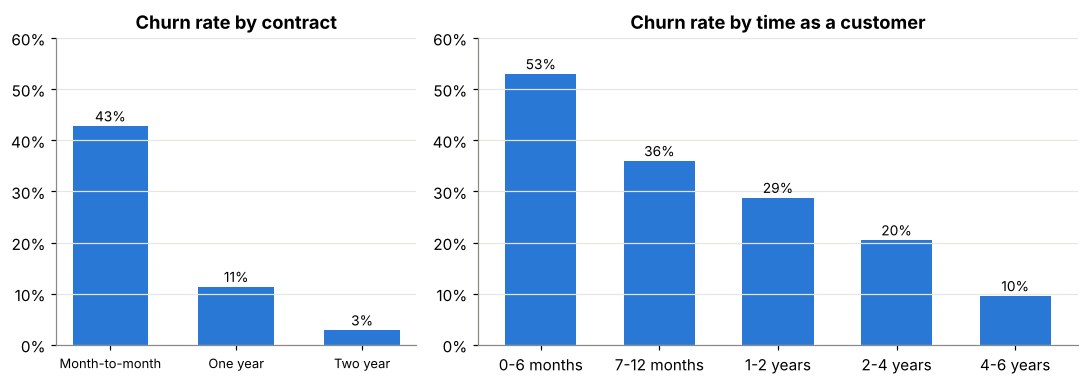

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [3, 5]})
c = tables["Contract"]
axes[0].bar(c.index, c["churn_rate"], color=BLUE, width=0.6)
for i, v in enumerate(c["churn_rate"]):
    axes[0].text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
axes[0].set_title("Churn rate by contract"); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[0].grid(axis="x", visible=False)
axes[0].tick_params(axis="x", labelsize=8.5)
t = tables["tenure_band"]
axes[1].bar(t.index.astype(str), t["churn_rate"], color=BLUE, width=0.6)
for i, v in enumerate(t["churn_rate"]):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
axes[1].set_title("Churn rate by time as a customer"); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1].grid(axis="x", visible=False)
for ax in axes: ax.set_ylim(0, 60)
fig.tight_layout(); fig.savefig("images/churn_by_contract_tenure.png"); plt.show()

In [6]:
# The highest-risk profile combines the three strongest signals
risky = (df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic") & (df["tenure"] <= 12)
segment = {
    "customers": int(risky.sum()),
    "share_of_customers_pct": round(100 * risky.mean(), 1),
    "churn_rate_pct": round(100 * df.loc[risky, "churned"].mean(), 1),
    "share_of_all_churners_pct": round(100 * df.loc[risky, "churned"].sum() / df["churned"].sum(), 1),
}
segment

{'customers': 916,
 'share_of_customers_pct': np.float64(13.0),
 'churn_rate_pct': np.float64(70.2),
 'share_of_all_churners_pct': np.float64(34.4)}

## 3. Ranking customers by churn risk

A logistic regression is trained on 75% of customers and tested on the other 25%. Logistic regression is used on purpose: its coefficients are easy to explain to a retention team, which matters more here than squeezing out the last point of accuracy.

In [7]:
features = ["gender", "SeniorCitizen", "Partner", "Dependents", "tenure", "PhoneService", "MultipleLines", "InternetService",
            "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod", "MonthlyCharges"]
X = pd.get_dummies(df[features], drop_first=True, dtype=float)
y = df["churned"]
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(X, y, df.index, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
model = LogisticRegression(max_iter=2000).fit(scaler.transform(X_train), y_train)
risk = model.predict_proba(scaler.transform(X_test))[:, 1]
auc = roc_auc_score(y_test, risk)
print(f"Test ROC AUC: {auc:.3f}")

coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()
drivers = pd.concat([coefs.head(5), coefs.tail(5)])
drivers.to_frame("coefficient (standardised)")

Test ROC AUC: 0.844


,coefficient (standardised)
MonthlyCharges,-0.816
tenure,-0.787
Contract_Two year,-0.553
Contract_One year,-0.285
OnlineSecurity_Yes,-0.123
PaperlessBilling_Yes,0.198
MultipleLines_Yes,0.221
StreamingTV_Yes,0.256
StreamingMovies_Yes,0.284
InternetService_Fiber optic,0.775


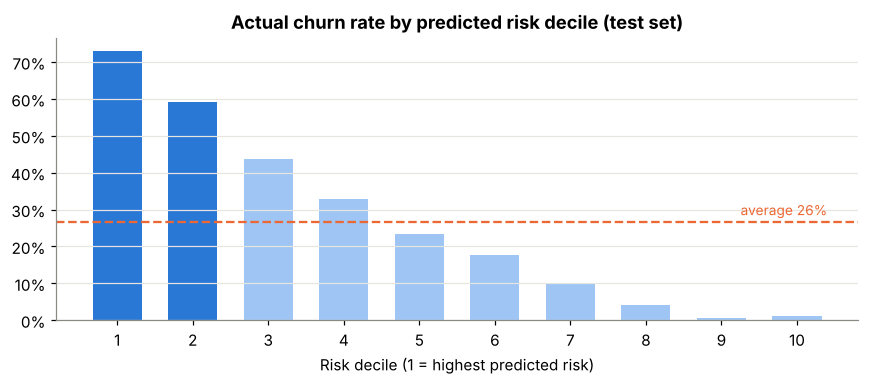

{'test_customers': 1761, 'auc': 0.844, 'top20_share_of_churners_pct': np.float64(49.9), 'top20_churn_rate_pct': np.float64(66.2), 'base_churn_rate_pct': np.float64(26.5), 'top20_monthly_revenue_of_churners': np.float64(18932.8)}


,customers,churn_rate,churners,cum_share_of_churners_pct
decile,,,,
1,177,72.900,129,27.600
2,176,59.100,104,49.900
3,176,43.800,77,66.400
4,176,33.000,58,78.800
5,176,23.300,41,87.600
6,176,17.600,31,94.200
7,176,9.700,17,97.900
8,176,4.000,7,99.400
9,176,0.600,1,99.600


In [8]:
test = pd.DataFrame({"risk": risk, "churned": y_test.values, "monthly": df.loc[idx_test, "MonthlyCharges"].values})
test = test.sort_values("risk", ascending=False).reset_index(drop=True)
test["decile"] = pd.qcut(test.index, 10, labels=range(1, 11))
deciles = test.groupby("decile", observed=True).agg(customers=("churned", "size"), churn_rate=("churned", "mean"), churners=("churned", "sum"))
deciles["churn_rate"] = (100 * deciles["churn_rate"]).round(1)
deciles["cum_share_of_churners_pct"] = (100 * deciles["churners"].cumsum() / deciles["churners"].sum()).round(1)

top20 = test.iloc[: int(0.2 * len(test))]
targeting = {
    "test_customers": len(test),
    "auc": round(auc, 3),
    "top20_share_of_churners_pct": round(100 * top20["churned"].sum() / test["churned"].sum(), 1),
    "top20_churn_rate_pct": round(100 * top20["churned"].mean(), 1),
    "base_churn_rate_pct": round(100 * test["churned"].mean(), 1),
    "top20_monthly_revenue_of_churners": round(top20.loc[top20["churned"] == 1, "monthly"].sum(), 2),
}

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(deciles.index.astype(str), deciles["churn_rate"], color=[BLUE if i < 2 else "#9ec5f4" for i in range(10)], width=0.65)
ax.axhline(targeting["base_churn_rate_pct"], color=ORANGE, lw=1.5, ls="--")
ax.text(9.4, targeting["base_churn_rate_pct"] + 2, f"average {targeting['base_churn_rate_pct']:.0f}%", ha="right", color=ORANGE, fontsize=9)
ax.set_xlabel("Risk decile (1 = highest predicted risk)"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Actual churn rate by predicted risk decile (test set)"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig("images/risk_deciles.png"); plt.show()
print(targeting)
deciles

## Findings

| Measure | Value |
|---|---|
| Customers | 7,043 |
| Left in the last month | 1,869 (26.5%) |
| Monthly revenue lost | $139,131 (30.5% of monthly revenue) |
| Annualised | $1.67m |

1. **The customers leaving are worth more than the ones staying.** Churners paid $74.44 a month on average against $61.27, so churn takes 30.5% of revenue, more than its 26.5% share of customers.
2. **Contract type is the biggest single signal.** 42.7% of month-to-month customers left against 2.8% on two-year contracts. Month-to-month customers account for 86.9% of the revenue lost.
3. **The first six months are the danger zone.** 52.9% of customers in their first six months left, against 9.5% of those who had stayed four years or more. This points at onboarding, not just pricing.
4. **Fibre customers pay more and still leave.** Fibre churn is 41.9% against 19.0% for DSL. That is worth a closer look at fibre price and service quality.
5. **Payment method and support matter.** Customers paying by electronic cheque churn at 45.3%, against 15 to 17% on automatic payments; customers without tech support churn at 41.6%, against 15.2% with it.
6. **One profile holds a third of the problem.** Month-to-month fibre customers in their first year are 13.0% of the base, churn at 70.2% and make up 34.4% of all churners.
7. **A simple model focuses the retention team.** The logistic regression ranks test customers with an ROC AUC of 0.844. The riskiest 20% contains 49.9% of the people who actually left, with a churn rate of 66.2% against the 26.5% average.

**What I would recommend:** offer contract upgrades during the first six months, give an incentive to move to automatic payment, bundle tech support and online security with fibre, and investigate the fibre experience directly.

**Limitations.** IBM's sample describes a fictional provider at a single point in time, so these are associations, not proven causes. The model's coefficients are affected by overlapping columns (monthly charges rise with each add-on service), which is why monthly charges gets a negative coefficient even though churners pay more; the descriptive breakdowns are the safer guide to *why*.

In [9]:
summary = {
    "quality": {k: int(v) for k, v in quality.items()},
    "kpis": kpis,
    "by_contract": [{"group": k, **{c: float(v) for c, v in r.items()}} for k, r in tables["Contract"].iterrows()],
    "by_tenure": [{"group": str(k), **{c: float(v) for c, v in r.items()}} for k, r in tables["tenure_band"].iterrows()],
    "by_payment": [{"group": k, **{c: float(v) for c, v in r.items()}} for k, r in tables["PaymentMethod"].iterrows()],
    "by_internet": [{"group": k, **{c: float(v) for c, v in r.items()}} for k, r in tables["InternetService"].iterrows()],
    "by_techsupport": [{"group": k, **{c: float(v) for c, v in r.items()}} for k, r in tables["TechSupport"].iterrows()],
    "segment": segment,
    "targeting": targeting,
    "deciles": [{"decile": int(k), "churn_rate": float(r["churn_rate"]), "cum_share": float(r["cum_share_of_churners_pct"])} for k, r in deciles.iterrows()],
    "drivers": {k: round(float(v), 3) for k, v in drivers.items()},
}
json.dump(summary, open("results/summary.json", "w"), indent=1)
print("saved results/summary.json")

saved results/summary.json
